# T2.1 Pulse-pair coherence

**Purpose** (Table 4.2, D-5 validation plan): the primary phase noise for DopSCA results from coherence loss due to overlapping returning sub-pulses.
This coherence is calculated dynamically in SWB-SCA. Here we compute the coherence budget and test whether the simulated pulse-pair phase noise follows
the theoretical phase distribution for that coherence.

**Implementation**
1. Compute the SWB-SCA coherence budget from the sub-pulse overlap: $\gamma_{SCR}$, $\gamma_{temporal}$ and $\gamma_D$ (California)
2. Simulate the pulse pairs (one noise realisation)
3. Compare the simulated pulse-pair phase noise with the single-look phase distribution of Lee et al. (1994) for the budget coherence

**Requirements**: reference simulation SWB-SCA, theoretical coherence

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, add_L1_uncertainties
from leakage.uncertainties import decorrelation

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

# Data preparation
## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
# This prevents aliasing in azimuth, and does not remove range resolution
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

domain = dict(grg = slice(590E3, 742E3), az = slice(50E3, 350E3)) # same extent as the Monte Carlo notebooks

## 1 - Load data

In [3]:
files_cali = [
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
    '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
]

simulation = xr.open_mfdataset(files_cali, compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').compute()
sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

# clipping unreasonable incidence angles
simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)

# Here we interpolate to finer grid spacing,
new_az = np.arange(simulation.az.min(), simulation.az.max(), sca.grid_spacing_target)
new_grg = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_target)
simulation = simulation.interp(az=new_az, grg=new_grg)
simulation = simulation.sel(domain)

## 2 - Convert to 3D observation cube, add the beam pattern and estimate idealized scatterometer observations

In [4]:
nrcs = simulation[sca.var_nrcs].sel(pol='M')
dop = simulation[sca.var_dop].sel(pol='M')
inc_2d = np.degrees(simulation[sca.var_inc].expand_dims(dim={sca.dim_az: simulation.az.data}))

data = create_dataset(
    nrcs=nrcs.data,
    dop=dop.data,
    inc=inc_2d.data,
    grg=simulation.grg.data,
    az=simulation.az.data,
    grid_spacing=sca.grid_spacing_target,
)

data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
# reload interpolated beam pattern received from EUMETSAT
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']
data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")
data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)

## 3 - Simulate the pulse pairs
`add_L1_uncertainties` simulates the echoes of both pulses per resolution cell, overlapping with the echo of the other pulse from $\pm$ the
pulse-pair offset, and returns the lag product of the two received samples as `pp_re` / `pp_im`. The SCR is computed from the NRCS field.

In [5]:
ds = add_L1_uncertainties(
    ds = data_cube,
    dim_range = sca.dim_range,
    dim_az_beam = sca.dim_az_beam,
    v_sat_orbit = sca.v_sat_orbit,
    U = sca.U,
    sat_height = sca.z0,
    T_pp= sca.T_pp,
    Lambda = sca.Lambda,
    fixed_SCR=None, # < -------- here we let the SCR be calculated from the NRCS data
    grid_spacing_slant_range=sca.grid_spacing_slant_range_SCA,
    random_state=sca.random_state
)

# Coherence budget
## 4 - Budget components
As computed inside `add_L1_uncertainties`:

$$\gamma = \gamma_{SCR}\,\gamma_{temporal}\,\gamma_D$$

- $\gamma_{SCR} = P(r) / \sqrt{\big(P(r)+P(r-\Delta)\big)\big(P(r)+P(r+\Delta)\big)}$, from the expected (speckle-free) NRCS at the signal range $r$ and at $r \mp \Delta$, with $\Delta = c\,T_{pp}/2$ the pulse-pair offset in slant range. It equals 0.5 for a uniform scene
- $\gamma_{temporal} = \exp\!\big(-(T_{pp}/T_s)^2\big)$, with the surface decorrelation time $T_s = 3.29\,\lambda / U$
- $\gamma_D = \exp\!\big(-(T_{pp}/T_D)^2\big)$, with the Doppler decorrelation time $T_D = 1 / (\sqrt{2}\,k\,v\,\sigma_{az})$ and $\sigma_{az}$ the standard deviation of the
  slant-plane azimuth angle within the -3 dB two-way beam, averaged over the scene

In [6]:
beam = ds.beam
beam_3dB = (
    xr.where(beam >= 10 ** (-3 / 10) * beam.max(dim=sca.dim_az_beam), 1, np.nan)
    * ds.az_angle_wrt_boresight_slant # in radians, antenna-frame angle
)
sigma_az_angle = beam_3dB.std(dim=sca.dim_az_beam).mean().values * 1

wavenumber = 2 * np.pi / sca.Lambda
T_corr_Doppler = 1 / (np.sqrt(2) * wavenumber * sca.v_sat_orbit * sigma_az_angle)
T_corr_surface = 3.29 * sca.Lambda / sca.U

gamma_temporal = decorrelation(sca.T_pp, T_corr_surface)
gamma_D = decorrelation(sca.T_pp, T_corr_Doppler)

# Results
## Coherence budget
Scene means over the valid cells (cells within one pulse-pair offset of the range edges have unknown clutter and are excluded). The total is $\gamma_{SCR}\,\gamma_{temporal}\,\gamma_D$.

In [7]:
valid = ds['pp_re'].notnull()
gamma_SCR = float(ds['gamma_SCR'].where(valid).mean())

summary = pd.Series({
    "gamma_SCR": gamma_SCR,
    "gamma_temporal": gamma_temporal,
    "gamma_D": gamma_D,
    "gamma total": gamma_SCR * gamma_temporal * gamma_D,
}).round(4).to_frame("California")
summary

,California
gamma_SCR,0.4977
gamma_temporal,1.0000
gamma_D,0.6752
gamma total,0.3361


## Pulse-pair phase noise vs Lee et al. (1994)
The phase of a single-look lag product with coherence $\gamma$ follows the probability density function of Lee et al. (1994), eq. 19, which is also used in
`leakage.uncertainties.phase_error_generator`:

$$p(\psi) = \frac{1-\gamma^2}{2\pi\,(1-\beta^2)^{3/2}}\Big(\sqrt{1-\beta^2} + \beta\,\big(\pi - \arccos\beta\big)\Big),\qquad \beta = \gamma\cos\psi$$

The histogram holds the phases of all valid simulated lag products (no true motion, so the phase is the phase noise), against the pdf for the total budget
coherence. The table gives the standard deviation of both, as phase and as line-of-sight velocity, $v = \lambda\,\psi / (4\pi T_{pp})$.
NOTE the lag products are interpolated from 150 m resolution cells to the 75 m grid, so neighbouring samples are not independent.

In [8]:
def lee_pdf(psi, gamma):
    # single-look phase-difference pdf, Lee et al. (1994) eq. 19
    beta = gamma * np.cos(psi)
    return (1 - gamma**2) * (np.sqrt(1 - beta**2) + beta * (np.pi - np.arccos(beta))) / (2 * np.pi * (1 - beta**2)**1.5)

phase = np.arctan2(ds['pp_im'], ds['pp_re']).values[valid.values]
gamma_total = float(summary.loc["gamma total", "California"])
psi = np.linspace(-np.pi, np.pi, 3601)

phase2los = sca.Lambda / (4 * np.pi * sca.T_pp) # line-of-sight velocity per radian
std_lee = np.sqrt(np.trapz(psi**2 * lee_pdf(psi, gamma_total), psi))
pd.DataFrame(
    {"phase std [rad]": [phase.std(), std_lee], "LoS velocity std [m/s]": [phase.std() * phase2los, std_lee * phase2los]},
    index=["simulated", f"Lee et al. (1994), gamma = {gamma_total:.3f}"],
).round(3)

,phase std [rad],LoS velocity std [m/s]
simulated,1.516,58.172
"Lee et al. (1994), gamma = 0.336",1.507,57.857


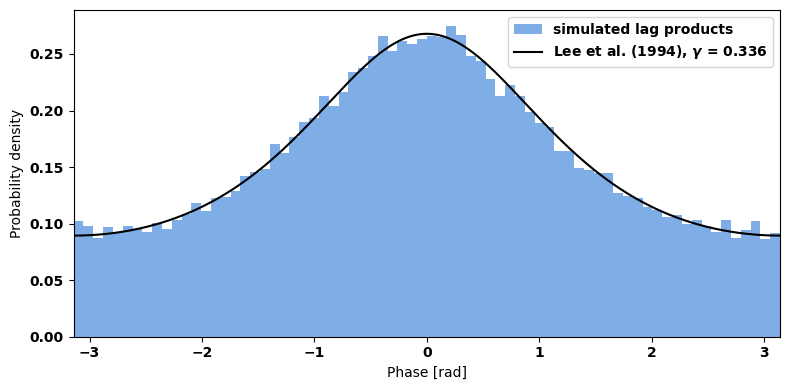

In [9]:
fig, ax = plt.subplots(figsize = (8, 4))
ax.hist(phase, bins = 72, range = (-np.pi, np.pi), density = True, color = '#2a78d6', alpha = 0.6, label = "simulated lag products")
ax.plot(psi, lee_pdf(psi, gamma_total), color = 'k', lw = 1.5, label = rf"Lee et al. (1994), $\gamma$ = {gamma_total:.3f}")
ax.set_xlim(-np.pi, np.pi)
ax.set_xlabel("Phase [rad]")
ax.set_ylabel("Probability density")
ax.legend()
plt.tight_layout()